<center><img src='https://innovatics-buck.s3.us-east-1.amazonaws.com/innovatics-logo.jpg' width=460/></center>

# InnovatiCS — Week 17 Python Lab: Advanced Python for AI
## Saudi Market Applied Lab — 5 Topics

**Topics:** Web Scraping & Beautiful Soup • SciPy • TensorFlow/Keras • PyTorch • LangChain

**Business cases:** Saudi EV/industrial market intelligence, desalination operations, retail churn, digital-banking transaction risk, and enterprise policy assistants.

**Format:** Each topic contains a Saudi-market case, guided questions, a coding cell, and an interpretation section—matching the Week 16 lab structure.

> The scraping exercise uses local HTML so the notebook is reproducible. For live sites, use only authorized/public access and follow applicable terms, privacy rules, and rate limits.

## 0 — Environment Setup

In [1]:
import warnings, re
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.random.seed(42)

# Install only if needed:
# %pip install beautifulsoup4 scipy scikit-learn tensorflow torch langchain langchain-core

# Topic 1 — Web Scraping & Beautiful Soup
## Saudi Use Case: EV-Charging Supplier Market Intelligence
A Saudi mobility company wants to structure publicly available supplier listings across major Saudi cities.

## Lab 1 — Parse, Extract, Clean & Analyze
**Q1.** Parse the HTML with Beautiful Soup.  
**Q2.** Extract title, company, city, category, SAR price, and URL.  
**Q3.** Demonstrate `find()`, `find_all()`, `select()`, and `select_one()`.  
**Q4.** Convert the records into a DataFrame.  
**Q5.** Clean `price_sar` to numeric.  
**Q6.** Calculate average listed price by city and identify the minimum.  
**Q7.** Plot average price by city.  
**Q8.** Explain when Requests, Session, or Selenium would be appropriate.  
**Q9.** State two legal/ethical controls before scraping a live site.

Title: Saudi EV Marketplace
     city                company      category       url  price_sar
0  Riyadh  Najd Charge Solutions    EV Charger     /najd      18500
1  Jeddah  Red Sea Mobility Tech    EV Charger   /redsea      17900
2  Dammam   Eastern Grid Systems  Fast Charger  /eastern      24750
3  Riyadh    Riyadh Smart Energy  Fast Charger      /rse      23400
        average_price  min_price
city                            
Dammam        24750.0      24750
Jeddah        17900.0      17900
Riyadh        20950.0      18500


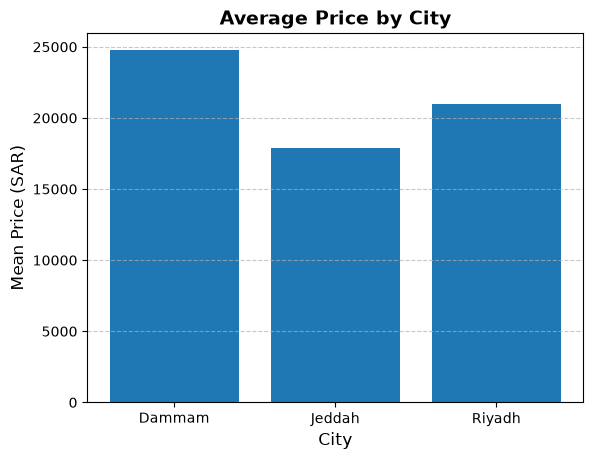

In [76]:
html='''<html><head><title>Saudi EV Marketplace</title></head><body><div id="market">
<div class="supplier" data-city="Riyadh"><h2>Najd Charge Solutions</h2><span class="category">EV Charger</span><span class="price">SAR 18,500</span><a href="/najd">Details</a></div>
<div class="supplier" data-city="Jeddah"><h2>Red Sea Mobility Tech</h2><span class="category">EV Charger</span><span class="price">SAR 17,900</span><a href="/redsea">Details</a></div>
<div class="supplier" data-city="Dammam"><h2>Eastern Grid Systems</h2><span class="category">Fast Charger</span><span class="price">SAR 24,750</span><a href="/eastern">Details</a></div>
<div class="supplier" data-city="Riyadh"><h2>Riyadh Smart Energy</h2><span class="category">Fast Charger</span><span class="price">SAR 23,400</span><a href="/rse">Details</a></div>
</div></body></html>'''
# Write your Python solution here

from bs4 import BeautifulSoup

soup = BeautifulSoup(html, 'html.parser')
print(f"Title: {soup.title.string}")

data = []
for div in soup.body.select(".supplier"):
    city = div['data-city']
    company = div.h2.string
    category = div.select_one('.category').string
    price = div.select_one('.price').string
    url = div.select_one('a').get('href')

    data.append({
        "city": city,
        "company": company,
        "category": category,
        "price": price,
        "url": url
    })
    
data = pd.DataFrame(data)
data["price_sar"] = data["price"].str.replace("SAR ", "").str.replace(",", "")
data["price_sar"] = pd.to_numeric(data["price_sar"], errors="coerce")
data = data.drop("price", axis=1)
print(data)

by_city = data.groupby("city").agg(
    average_price=("price_sar", "mean"),
    min_price=("price_sar", "min")
)
print(by_city)

plt.bar(by_city.index, by_city.average_price)
plt.title("Average Price by City", fontsize=14, fontweight="bold")
plt.xlabel("City", fontsize=12)
plt.ylabel("Mean Price (SAR)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

### Answers to questions Q8 and Q9

#### Q8. When would I use Requests, Session, or Selenium?

It mostly depends on two things: whether the page is static or built with JavaScript, and whether I need to stay logged in when scraping the website.

**Requests**: I will use it with static pages where the data is already in the HTML. It just downloads the page. If the supplier listings in this lab were on a real static website, requests.get() would be enough.

**Session**: It's still Requests, but it remembers cookies and login information between requests. I would use it if I had to log in first, or go through several pages on the same site. It’s also a bit faster because it reuses the same connection.

**Selenium**: I will use if I notice that the page content appears after Javascript runs, for example when you have to scroll, click “load more”, or wait for the page to load. It opens a real browser, so it’s much slower and heavier. I would only use it when the other two can’t get the data.

#### Q9. Two legal/ethical checks before scraping a live site

- **Read the robots.txt and the Terms of Service**: The robots.txt shows which parts of the site the owner doesn’t want bots to visit. The Terms of Service can forbid scraping completely. If they do, I shouldn’t scrape the site, even if it’s technically possible.
- **Don’t overload the server**: I should add a pause between requests (for example with time.sleep()) and avoid sending too many at once. Otherwise my script can slow down the site for real users, a bit like a small attack.

### Interpretation / Discussion

We parsed the page **Saudi EV Marketplace**, where we collected information about the products provided by the different suppliers of **Saudi Ev**
From the collected data, we have
- the city of the supplier
- the supplier name
- the product category
- the product price
- the URL of the webpage where we can find details about that product
Then we parse the price to extract the numerical value and compute the average product price by city.

Thanks to that information, we can say that
- Dammam is the city with the highest average price and Jeddah is the lowest one

That result can lead the company to take a wrong decision because they have no information about the number of products associated to each average result. **Riyadh** has **2** products, but its average is lower than **Dammam** which at the contrary has only **1** product. 
So say that **Riyadh** has more expensive products, for example, would be wrong because the number of products used to compute the average price decreases its real value. 

As a recommendation, more indicators must be computed and joined to the plot. 

# Topic 2 — SciPy
## Saudi Use Case: Desalination Energy & Pressure Analytics
A Saudi desalination operator wants to compare specific energy consumption (SEC), recover missing sensor values, optimize an operating setpoint, and detect pressure peaks.

## Lab 2 — Statistics, Interpolation, Optimization & Signal Processing
**Q1.** Compare SEC for Train A vs Train B using a two-sample t-test.  
**Q2.** Interpret the p-value at α=0.05.  
**Q3.** Introduce missing pressure values and recover them using interpolation.  
**Q4.** Use `minimize_scalar()` to minimize the supplied energy-cost function.  
**Q5.** Smooth the pressure signal and detect peaks with `find_peaks()`.  
**Q6.** Plot the results.  
**Q7.** Explain how the analysis supports Saudi water/energy operations.

STD SEC A: 0.12333161000368191
STD SEC B: 0.1472991901362835

Because the std of the two generated data is not equal I will use equal_var=False
Stats t : -8.9727
P-value : 0.0000

With a p-value lower than α=0.05, we can say that there is a difference between the SEC features of the two groups, Train_A and Train_B.
 message: Solution found.
 success: True
  status: 0
     fun: 3.2334450774731
       x: 3.2334450774731
     nit: 25
    nfev: 25
Peaks found: [  7  32  53  78 101 126 149 173 198 222]


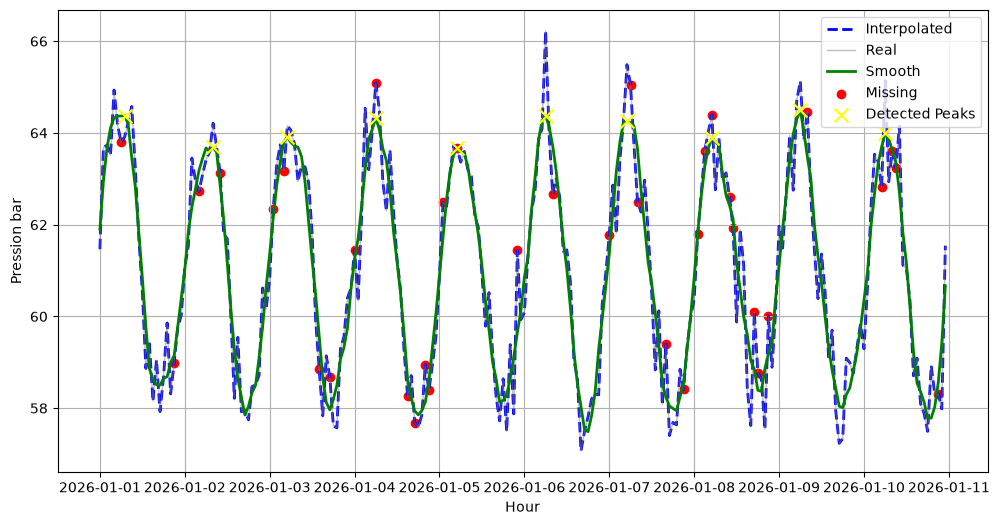

In [135]:
from scipy import stats, interpolate, optimize, signal

n = 240;
hour = np.arange(n)
plant = pd.DataFrame({
 "hour":hour,
 "train":np.where(hour%2==0,"Train_A","Train_B"),
 "pressure_bar":61+3*np.sin(2*np.pi*hour/24)+np.random.normal(0,.7,n)
})
plant["sec_kwh_m3"] = np.where(
    plant.train=="Train_A",
    np.random.normal(3.55,.12,n),
    np.random.normal(3.72,.14,n)
)

# Q1
train_a_sec = plant[plant['train'] == 'Train_A']['sec_kwh_m3'].values
train_b_sec = plant[plant['train'] == 'Train_B']['sec_kwh_m3'].values

print(f"STD SEC A: {np.std(train_a_sec)}")
print(f"STD SEC B: {np.std(train_b_sec)}")

print("\nBecause the std of the two generated data is not equal I will use equal_var=False")
sec_t_stat, sec_p_value = stats.ttest_ind(train_a_sec, train_b_sec, equal_var=False)
print(f"Stats t : {sec_t_stat:.4f}")
print(f"P-value : {sec_p_value:.4f}")

# Q2
print("\nWith a p-value lower than α=0.05, we can say that there is a difference between the SEC features of the two groups, Train_A and Train_B.")

# Q3
sample_index = plant.sample(frac=0.15).index
plant['pressure_bar_missing'] = plant['pressure_bar'].copy()
plant.loc[sample_index, "pressure_bar_missing"] = np.nan

plant['hour_index'] = pd.to_datetime('2026-01-01 00:00:00') + pd.to_timedelta(plant['hour'], unit='h')
plant = plant.set_index('hour_index')
plant['pressure_bar_interpolated'] = plant['pressure_bar'].interpolate(method='time')

# Q4
# As we don't have the cost fonction, we are going to suppose that the Price is constant
# Which means that SEC and the cost have the same curve
def cost_fn(sec):
    return sec

r = optimize.minimize_scalar(
    cost_fn,
    bounds=(plant['sec_kwh_m3'].min(), plant['sec_kwh_m3'].max()),
    method='bounded'
)
print(r)

# Q5
plant['pressure_smooth'] = signal.savgol_filter(
    plant['pressure_bar'],
    window_length=11,
    polyorder=3
)
peaks, properties = signal.find_peaks(
    plant['pressure_smooth'],
    distance=12,
    prominence=1.0
)
print(f"Peaks found: {peaks}")

# Q6

plt.figure(figsize=(12, 6))
plt.plot(
    plant.index, plant['pressure_bar_interpolated'],
    label="Interpolated",
    color='blue', linestyle='--', linewidth=2
)
plt.plot(
    plant.index, plant['pressure_bar'], label='Real',
    color='gray', alpha=0.5, linewidth=1
)
plt.plot(
    plant.index,
    plant['pressure_smooth'], label='Smooth',
    color='green', linewidth=2
)

missing_mask = plant['pressure_bar_missing'].isna()
plt.scatter(
    plant.index[missing_mask],
    plant.loc[missing_mask, 'pressure_bar'],
    color='red',
    label='Missing'
)
plt.scatter(
    plant.index[peaks], plant['pressure_smooth'].iloc[peaks],
    color='yellow', marker='x', s=100, label='Detected Peaks', zorder=5
)

plt.xlabel('Hour')
plt.ylabel('Pression bar')
plt.legend()
plt.grid(True)
plt.show()

### Interpretation / Discussion

#### t-test interpretation

With a p-value lower than α=0.05, we can say that there is a difference between the SEC features of the two groups, Train_A and Train_B.


Write your technical and Saudi-market business interpretation here.

# Topic 3 — TensorFlow & Keras
## Saudi Use Case: Retail Customer Churn
A Saudi omnichannel retailer wants to estimate customer churn risk to prioritize retention activity.

## Lab 3 — Build, Train & Evaluate a Keras Neural Network
**Q1.** Inspect the synthetic customer dataset.  
**Q2.** Split train/test and standardize features.  
**Q3.** Build a `Sequential` network with ReLU hidden layers and Sigmoid output.  
**Q4.** Compile with Adam and binary cross-entropy.  
**Q5.** Train with a validation split.  
**Q6.** Plot loss and accuracy curves.  
**Q7.** Produce a confusion matrix and classification report.  
**Q8.** Display churn probabilities for five customers.  
**Q9.** Explain why probabilities and business thresholds matter.

(2500, 6) (2500,)
(1875, 6) (625, 6) (1875,) (625,)


Model: "sequential_38"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_116 (Dense)               │ (None, 32)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_117 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_118 (Dense)               │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 769 (3.00 KB)

 Trainable params: 769 (3.00 KB)

 Non-trainable params: 0 (0.00 B)

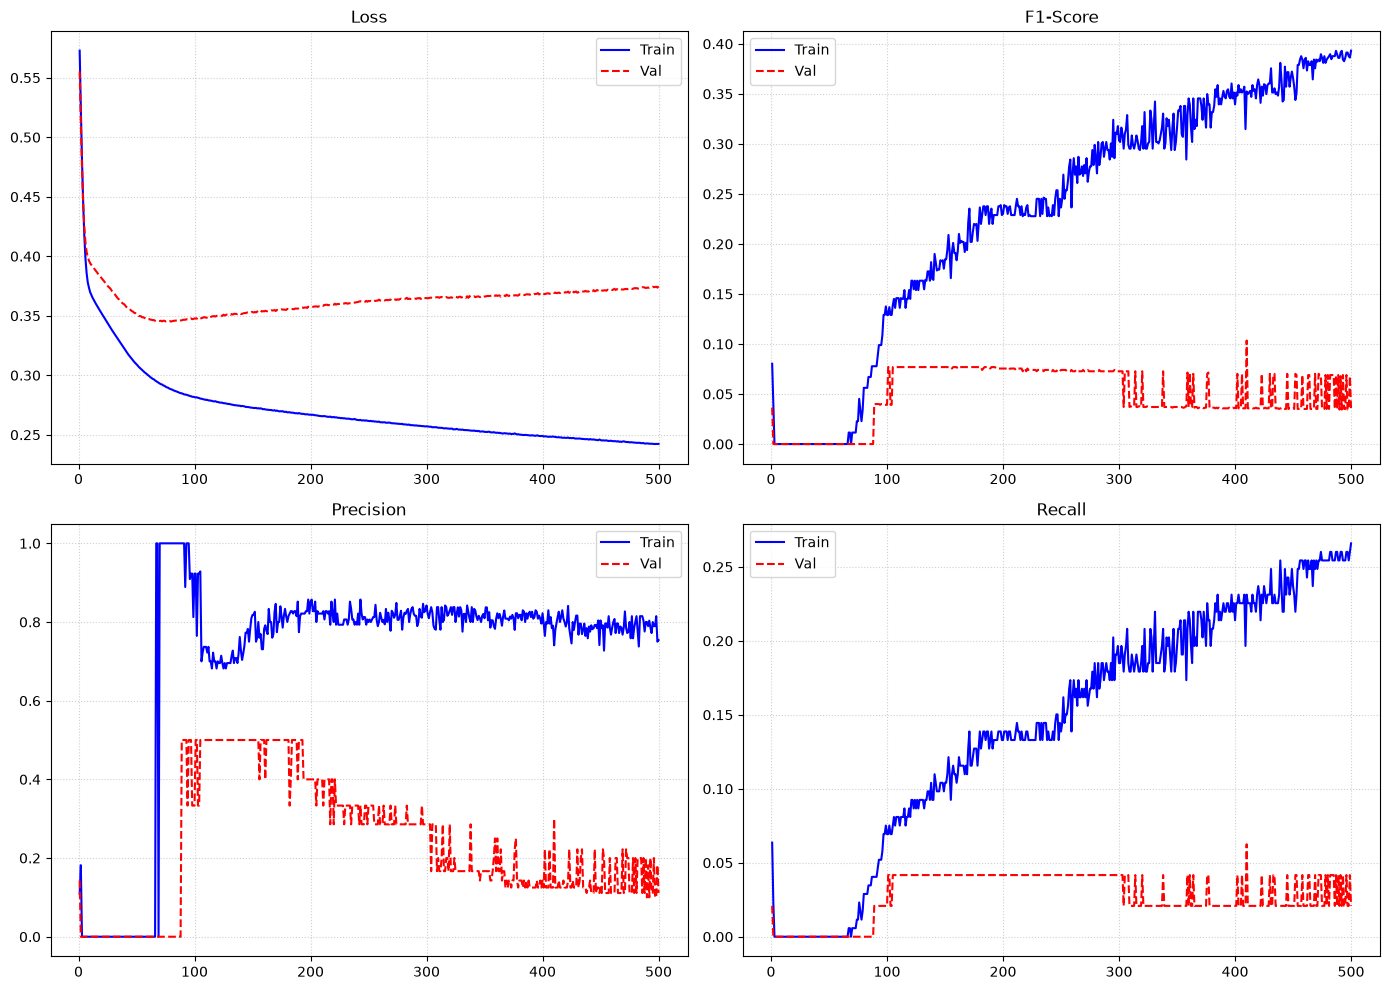

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 894us/step
              precision    recall  f1-score   support

   Not churn       0.87      0.98      0.92       540
       Churn       0.47      0.11      0.17        85

    accuracy                           0.86       625
   macro avg       0.67      0.54      0.55       625
weighted avg       0.82      0.86      0.82       625



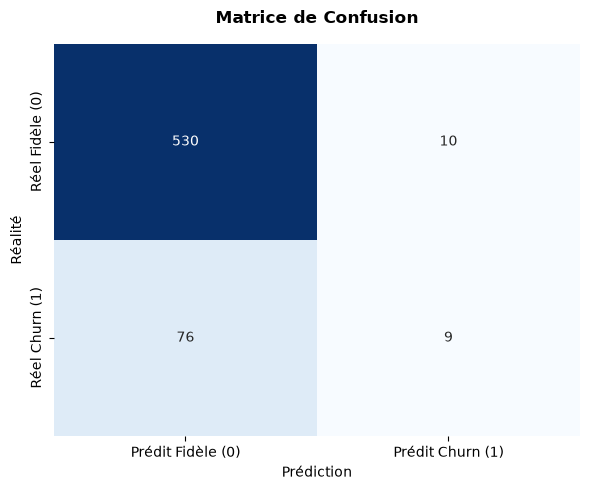



PROBABILITIES for 5 Customers
      monthly_spend_sar  visits_90d Churn Prob  Real status  \
1447         363.570252           8      0.00%            0   
1114         837.675004           4      0.00%            0   
1064         506.204850           6      0.00%            0   
2287         910.616570           7      0.00%            0   
1537         343.384906           6      0.00%            0   

      Prediction (threshold 0.5)  
1447                           0  
1114                           0  
1064                           0  
2287                           0  
1537                           0  


In [191]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras

import seaborn as sns

n=2500
retail=pd.DataFrame({
 "monthly_spend_sar":np.random.gamma(3,180,n),
 "visits_90d":np.random.poisson(7,n),
 "days_since_last_purchase":np.random.randint(1,120,n),
 "discount_usage_rate":np.random.beta(2,4,n),
 "app_sessions_30d":np.random.poisson(10,n),
 "loyalty_years":np.random.uniform(0,8,n)})
z=-2.2+.028*retail.days_since_last_purchase-.11*retail.visits_90d-.05*retail.app_sessions_30d-.18*retail.loyalty_years+.7*retail.discount_usage_rate
retail["churn"]=(np.random.rand(n)<1/(1+np.exp(-z))).astype(int)
# Write your TensorFlow/Keras solution here

# Q2
y = retail["churn"]
X = retail.drop("churn", axis=1)
print(X.shape, y.shape)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

cols_robust = ["monthly_spend_sar"]
cols_standard = ["visits_90d", "app_sessions_30d", "discount_usage_rate"]
cols_minmax = ["days_since_last_purchase", "loyalty_years"]

preprocessor = ColumnTransformer(
    transformers=[
        ('robust', RobustScaler(), cols_robust),
        ('standard', StandardScaler(), cols_standard),
        ('minmax', MinMaxScaler(), cols_minmax)
    ],
    remainder='passthrough'
)
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor)
])
pipeline.set_output(transform="pandas")
X_train_scaled = pipeline.fit_transform(X_train)
X_test_scaled = pipeline.fit_transform(X_test)


# Q3
input_shape = X_train_scaled.shape[1]
model = keras.Sequential([
    keras.layers.Input(shape=(input_shape,)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])

# Q4
THRESHOLD = 0.5

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="binary_crossentropy",
    # metrics=['accuracy']
    metrics=[
        keras.metrics.F1Score(threshold=THRESHOLD, name='f1_score'),
        keras.metrics.Precision(thresholds=THRESHOLD, name='precision'),
        keras.metrics.Recall(thresholds=THRESHOLD, name='recall')
    ]
)
model.summary()

# Q5. Train with a validation split.

classes = retail['churn'].unique()
weights = compute_class_weight(class_weight="balanced", classes=classes, y=retail['churn'])
class_weight_dict = dict(zip(classes, weights))

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=500,
    batch_size=64,
    validation_split=0.2,
    # class_weight=class_weight_dict,
    verbose=0
)

# Q6. Plot loss and accuracy curves.
history_data = history.history

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

metrics_to_plot = [
    ('loss', 'val_loss', 'Loss', 0),
    ('accuracy', 'val_accuracy', 'Accuracy', 1),
    ('f1_score', 'val_f1_score', 'F1-Score', 1),
    ('precision', 'val_precision', 'Precision', 2),
    ('recall', 'val_recall', 'Recall', 3)
]

for train_metric, val_metric, title, idx in metrics_to_plot:
    ax = axes[idx]

    if train_metric in history_data:
        epochs = range(1, len(history_data[train_metric]) + 1)
        ax.plot(epochs, history_data[train_metric], 'b-', label='Train')
        ax.plot(epochs, history_data[val_metric], 'r--', label='Val')
        ax.set_title(title)
        ax.set_label('Epoch')
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(loc='best')

plt.tight_layout()
plt.savefig('lab_3_dnn_perf.png', dpi=300, bbox_inches='tight')
plt.show()

# Q7. Produce a confusion matrix and classification report.
y_test_pred = model.predict(X_test_scaled)
y_test_class = (y_test_pred > THRESHOLD).astype(int)

# Q8. Display churn probabilities for five customers.
print(classification_report(y_test, y_test_class, target_names=['Not churn', 'Churn']))

cm = confusion_matrix(y_test, y_test_class)

# Affichage graphique de la matrice de confusion
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Prédit Fidèle (0)', 'Prédit Churn (1)'],
            yticklabels=['Réel Fidèle (0)', 'Réel Churn (1)'])

plt.title('Matrice de Confusion', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Réalité')
plt.xlabel('Prédiction')
plt.tight_layout()
plt.show()

# Q8. Display churn probabilities for five customers.
customers_idx = range(5)
prob_5_customers = y_test_class[customers_idx].flatten()
real_classes = y_test.iloc[customers_idx].values
pred_classes = y_test_class[customers_idx].flatten()

# Construction d'un DataFrame de synthèse propre
data = X_test.iloc[customers_idx].copy()
data['Churn Prob'] = [f"{p:.2%}" for p in prob_5_customers]
data['Real status'] = real_classes
data['Prediction (threshold 0.5)'] = pred_classes
print("\n\nPROBABILITIES for 5 Customers")
print(data[['monthly_spend_sar', 'visits_90d', 'Churn Prob', 'Real status', 'Prediction (threshold 0.5)']])

### Interpretation / Discussion
Write your technical and Saudi-market business interpretation here.

# Topic 4 — PyTorch
## Saudi Use Case: Digital Transaction Risk
A Saudi bank wants an educational neural-network prototype to flag higher-risk digital transactions for additional review.

## Lab 4 — Tensors, DataLoader, Autograd & Training Loop
**Q1.** Split and standardize the synthetic transaction data.  
**Q2.** Convert arrays to PyTorch tensors.  
**Q3.** Build `TensorDataset` and `DataLoader`.  
**Q4.** Create an `nn.Module` network.  
**Q5.** Train using `zero_grad()` → forward → loss → `backward()` → `step()`.  
**Q6.** Plot epoch loss.  
**Q7.** Evaluate with confusion matrix and classification report.  
**Q8.** Explain Autograd.  
**Q9.** Explain the operational trade-off between recall and false positives.

Epoch [5/25], Loss: 0.2167
Epoch [10/25], Loss: 0.2140
Epoch [15/25], Loss: 0.2098
Epoch [20/25], Loss: 0.2078
Epoch [25/25], Loss: 0.2071


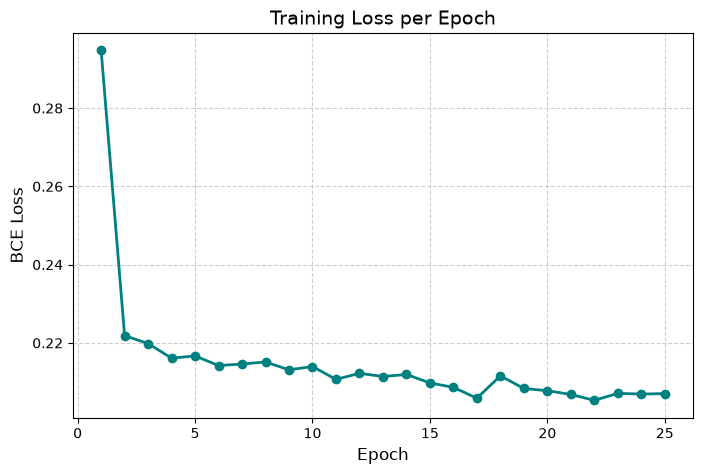

              precision    recall  f1-score   support

      flag 0       0.94      0.99      0.97       747
      flag 1       0.50      0.13      0.21        53

    accuracy                           0.93       800
   macro avg       0.72      0.56      0.59       800
weighted avg       0.91      0.93      0.92       800



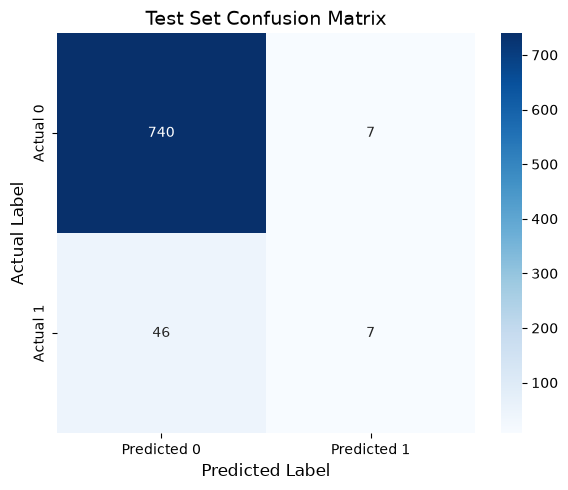

In [204]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

n=4000
txn=pd.DataFrame({
 "amount_sar":np.random.lognormal(5.5,1,n),"hour":np.random.randint(0,24,n),
 "device_age_days":np.random.randint(1,1500,n),"velocity_1h":np.random.poisson(2,n),
 "distance_from_home_km":np.random.exponential(25,n),"international":np.random.binomial(1,.08,n)})
risk=-5+.0012*txn.amount_sar+.35*txn.velocity_1h+.018*txn.distance_from_home_km+1.4*txn.international+.7*(txn.hour<5)
txn["flag"]=(np.random.rand(n)<1/(1+np.exp(-np.clip(risk,-20,20)))).astype(int)


# Q1. Split and standardize the synthetic transaction data.
y = txn['flag']
X = txn.drop('flag', axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Q2. Convert arrays to PyTorch tensors.
train_x = torch.tensor(X_train_scaled, dtype=torch.float32)
train_y = torch.tensor(y_train.values)

test_x = torch.tensor(X_test_scaled, dtype=torch.float32)
test_y = torch.tensor(y_test.values)

# Q3. Build TensorDataset and DataLoader.
train_dataset = TensorDataset(train_x, train_y)
test_dataset = TensorDataset(test_x, test_y)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Q4. Create an nn.Module network.
class TxnClassifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        
        self.network = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.network(x)

model = TxnClassifier(input_dim=X.shape[1])

# Q5. Train using zero_grad() → forward → loss → backward() → step().
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

num_epochs = 25
epoch_losses = []

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        outputs = model(X_batch).squeeze(-1)
        loss = criterion(outputs, y_batch.float())
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_batch.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_losses.append(epoch_loss)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch [{epoch + 1}/{num_epochs}], Loss: {epoch_loss:.4f}")

# Q6. Plot epoch loss.

plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), epoch_losses, marker='o', linestyle='-', color='teal', linewidth=2)
plt.title('Training Loss per Epoch', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('BCE Loss', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Q7. Evaluate with confusion matrix and classification report.
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        logits = model(X_batch).squeeze(-1)
        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).int()

        y_true.extend(y_batch.numpy())
        y_pred.extend(preds.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(
    classification_report(y_true, y_pred, target_names=['flag 0', 'flag 1'])
)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=['Predicted 0', 'Predicted 1'],
    yticklabels=['Actual 0', 'Actual 1']
)
plt.title('Test Set Confusion Matrix', fontsize=14)
plt.ylabel('Actual Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.show()

### Interpretation / Discussion
Write your technical and Saudi-market business interpretation here.

# Topic 5 — LangChain
## Saudi Use Case: Enterprise Policy & Operations Assistant
A Saudi organization wants an internal assistant that answers from approved policy text and can use controlled business tools.

## Lab 5 — Retrieval, RAG, Tools, Agentic Workflow & Guardrails
**Q1.** Split the supplied policy text into chunks.  
**Q2.** Build a transparent local keyword retriever.  
**Q3.** Retrieve context for each sample question.  
**Q4.** Create a RAG prompt that forbids unsupported answers.  
**Q5.** Explain embeddings, vector stores, and retrievers.  
**Q6.** Create a controlled VAT calculator tool and PO-status tool.  
**Q7.** Describe: User → Router → Retriever/Tool → LLM → Guardrail → Answer.  
**Q8.** Explain chain vs agent.  
**Q9.** Define at least three enterprise guardrails.  
**Q10.** Explain when LangGraph / human-in-the-loop is appropriate.

In [219]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_community.retrievers import BM25Retriever
from langchain_core.prompts import ChatPromptTemplate

policy_text='''Travel Policy: Domestic business travel within Saudi Arabia requires manager approval before booking.
Expense Policy: Employees must submit business expense claims with supporting receipts within 30 days.
Data Policy: Confidential company information must not be copied to unauthorized personal cloud storage.
AI Policy: Generative AI tools may be used only with approved data and according to company security controls.
Procurement Policy: Purchases above the delegated approval threshold require procurement review and documented approval.'''
questions=[
    "When should I submit an expense claim?",
    "Can I put confidential company data in my personal cloud drive?",
    "What is required before domestic business travel?"
]


# Q1. Split the supplied policy text into chunks.
text_splitter = RecursiveCharacterTextSplitter(chunk_size=100, chunk_overlap=0)
texts = text_splitter.split_text(policy_text)
docs = [Document(page_content=text) for text in texts]

# Q2. Build a transparent local keyword retriever.
retriever = BM25Retriever.from_documents(docs)
retriever.k = 3

# Q3. Retrieve context for each sample question.
contexts = retriever.batch(questions)

# Q4. Create a RAG prompt that forbids unsupported answers.
system_instruction = (
    "You are a strict factual assistant. Answer the user's question USING ONLY the "
    "provided Context. Do not use any outside knowledge or extrapolate.\n\n"
    "CRITICAL RULES:\n"
    "1. If the Context contains the answer, explain it accurately using only the facts provided.\n"
    "2. If the Context does not contain enough information to answer the question completely, "
    "respond exactly with: 'I am sorry, but the provided context does not contain enough information to answer this question.'\n"
    "3. Do not make up facts, assumptions, or speculations under any circumstances.\n\n"
    "Context:\n{context}"
)

rag_prompt = ChatPromptTemplate.from_messages([
    ("system", system_instruction),
    ("human", "Question: {question}")
])

### Interpretation / Discussion
Write your technical and Saudi-market business interpretation here.

# Final Week 17 Challenge — Compare the Five Technologies

Create a table:

| Technology | Primary Purpose | Saudi Use Case | Main Input | Main Output | Key Risk / Control |
|---|---|---|---|---|---|

Then answer:
1. When would you choose Beautiful Soup rather than an API?
2. When is SciPy more appropriate than deep learning?
3. Compare the TensorFlow/Keras and PyTorch workflows.
4. Why does RAG retrieve before generation?
5. Which agentic actions should remain deterministic or require human approval?